# ECHO: Spatial Audio & Acoustic Simulation
An interactive spatial-audio instrument built around delay lines, room acoustics,
and moving sound sources.
This notebook introduces ECHO's browser interface, demonstrates its Python API,
and explores two DSP concepts behind its spatial audio engine.

Run the cells from top to bottom and use headphones.

In [7]:
import numpy as np
import pyquist as pq
import matplotlib.pyplot as plt

from echo import (Echo, Room, Propagation, ReverbSettings, DelaySettings,
                  Static, Orbit, Spiral, Oscillate, Flyby, Waypoints, sources, dsp)

## 1. Interactive Spatial Audio Studio

Explore ECHO through its browser-based control panel. Select a demo scene,
add sound sources, position them in the room, configure acoustic properties,
and render the resulting spatial audio.

For a full-window experience, run `python src/app.py` in a terminal.

In [5]:
from echo.webui import serve_background
from IPython.display import IFrame

IFrame(serve_background(), width="100%", height=1000)

## 2. Composing with the Python API

ECHO is also a programmable Python library. The following example builds
a spatial audio scene entirely in code, combining synthesized plucked strings,
circular source motion, room acoustics, feedback delay, and FDN reverb.

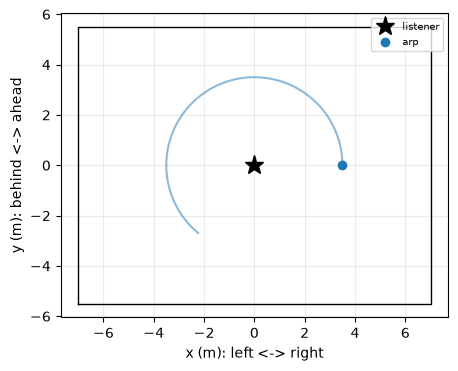

In [8]:
e = Echo()
e.room = Room(width=14, depth=11, absorption=0.25)
e.reverb = ReverbSettings(kind="fdn", t60=3.0, damping=0.25, level_db=-8)
e.delay = DelaySettings(enabled=True, time=0.375, feedback=0.5, level_db=-9)

arp = sources.pluck_line([(i * 0.25, p, 2.0) for i, p in enumerate(["A3","C4","D4","E4","G4","A4","E4","D4"] * 2)],
                         t60=2.0, damping=0.4, pick_position=0.2)
e.add_source(arp, "arp", motion=Orbit(radius=3.5, speed=0.08), send=0.35)

out = e.render(8.0)
pq.play(out, normalize=True)
e.plot_scene(seconds=8.0);

## 3. DSP Foundations: Delay Lines & Doppler

Explore two signal-processing concepts that underpin ECHO's spatial audio engine:
feedback delay networks and fractional-delay-based Doppler shifting.

### 3.1 Feedback Delay: From Recurrence to Vectorization

In [10]:
def feedback_delay_notes(x, M, g):         
    buf, i, y = np.zeros(M), 0, np.zeros(len(x))
    for n in range(len(x)):
        y[n] = x[n] + g * buf[i]; buf[i] = y[n]; i = (i + 1) % M
    return y

x = np.random.randn(4000)
print(np.allclose(feedback_delay_notes(x, 441, 0.8), dsp.feedback_delay(x, 441, 0.8)))

True


### 3.2 Doppler Effect: Pitch Shifting Through Motion

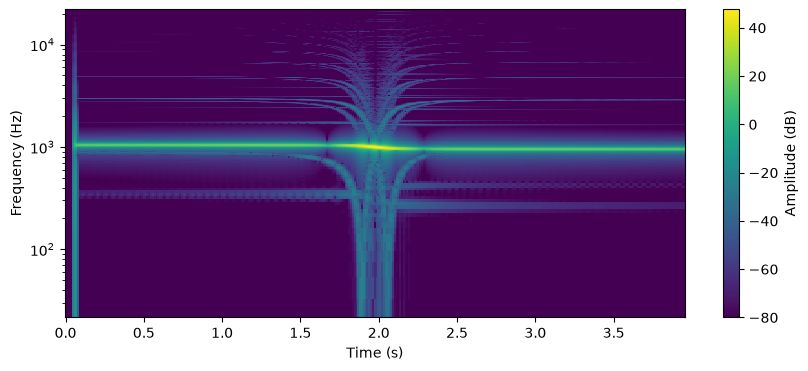

In [9]:
fs = 44100
t = np.arange(4 * fs) / fs
px, py = Flyby(-30, 2, 30, 2, duration=4.0)(t)
from echo.spatial import propagate
y = propagate(np.sin(2*np.pi*1000*t), px, py, fs, Propagation())
pq.plot_spec(pq.Audio(y.astype(np.float32), fs)) if hasattr(pq, "plot_spec") else None
pq.play(pq.Audio(y.astype(np.float32), fs), normalize=True)